# Детекция ботов на основе потока событий

В работе рассматривается задача определения автоматизированного трафика по истории событий, связанных с отдельными `cookie`.

## Постановка задачи

### Цель задачи

Целью работы является построение модели детекции автоматизированного трафика по событиям, совершенным пользователями в течение суточного окна наблюдения. 

Каждой cookie необходимо присвоить значение от 0 до 1: чем выше значение, тем вероятнее принадлежность к положительному классу - трафику известных сервисов автоматизированного сбора данных.

Исходные данные не содержат готовых поведенческих признаков. Поэтому основная часть решения заключается в анализе событий и построении агрегированных признаков на уровне `cookie_id`.

### Исходные данные

В задаче предоставлены четыре файла:

- `data/train.csv` - обучающая выборка с целевой переменной;
- `data/test.csv` - тестовая выборка без целевой переменной;
- `data/events.csv.gz` - история событий, на основе которой необходимо построить поведенческие признаки;
- `sample_submission.csv` - пример требуемого формата файла с предсказаниями.

Обучающая и тестовая выборки представлены на уровне `cookie_id`: одна строка соответствует одной cookie и содержит метаданные и границы ее суточного окна наблюдения.

Таблица `events.csv.gz` содержит отдельные события. Каждая строка этой
таблицы соответствует одному событию, связанному с определенной cookie.

### Целевая переменная

Целевая переменная представлена столбцом `target` в обучающей выборке.

Используется бинарная классификация:

- `target = 1` - трафик известных сервисов автоматизированного сбора данных;
- `target = 0` - трафик, отнесенный к человеческому.

### Формат предсказания

Для каждой `cookie_id` из тестовой выборки необходимо получить значение `score` от 0 до 1.

Интерпретация значения:

- значение, близкое к `0`, соответствует низкой оценке вероятности принадлежности к положительному классу;
- значение, близкое к `1`, соответствует высокой оценке вероятности принадлежности к положительному классу.

Итоговый файл должен содержать ровно две колонки:

- `cookie_id`;
- `score`.

Для каждой `cookie_id` из `test.csv` должна присутствовать ровно одна
строка. В итоговом файле не должно быть пропусков, дубликатов или
дополнительных идентификаторов.

### Метрика качества

Основной метрикой задачи является Precision при условии, что Recall составляет не менее 70%.

Recall характеризует долю найденных объектов положительного класса:

$$
Recall = \frac{TP}{TP + FN}
$$

Precision характеризует долю объектов положительного класса среди всех
объектов, которые модель отнесла к положительному классу:

$$
Precision = \frac{TP}{TP + FP}
$$

В данной задаче требуется найти такой порог классификации, при котором:

$$
Recall \geq 0.70
$$

а значение Precision является максимально возможным среди порогов,
удовлетворяющих этому условию.

### Ограничения и условия решения

При построении решения необходимо соблюдать ограничения задачи.

Запрещено:

- использовать большие языковые модели с количеством параметров более 1 миллиарда;
- обращаться к внешним API;
- выполнять ручную разметку тестовых данных;
- использовать заранее заданные ответы для конкретных `cookie_id`;
- вручную восстанавливать тестовую разметку;
- копировать решения других участников.

Допускается использование:

- классических алгоритмов машинного обучения;
- правил и эвристик;
- гибридных подходов;
- локально запускаемых open-source моделей и библиотек, соответствующих ограничениям задачи.

Для обеспечения воспроизводимости решения необходимо зафиксировать `random_state`, указать используемую версию Python и версии библиотек, необходимых для запуска ноутбука.

## Подготовка окружения и загрузка данных

На данном этапе подключаются необходимые библиотеки, фиксируются параметры воспроизводимости экспериментов, определяются пути к исходным файлам и загружаются обучающая, тестовая выборки и история событий.

### Импорт библиотек

In [80]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import optuna

from sklearn.metrics import (
    roc_auc_score, average_precision_score
)
from catboost import CatBoostClassifier

from metric import precision_at_recall

### Настройка воспроизводимости

Для воспроизводимости экспериментов фиксируется значение `random_state`. Оно будет использоваться в тех процедурах, где присутствует случайность.

In [81]:
RANDOM_STATE = 42

### Определение путей к данным

Все исходные данные находятся в директории `data`.

In [82]:
DATA_DIR = Path("data")

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
EVENTS_PATH = DATA_DIR / "events.csv.gz"

### Проверка наличия файлов

Перед загрузкой данных проверяем наличие всех файлов, необходимых для дальнейшей работы.

In [83]:
data_files = {
    "train": TRAIN_PATH,
    "test": TEST_PATH,
    "events": EVENTS_PATH
}

for name, path in data_files.items():
    status = "OK" if path.exists() else "NOT FOUND"
    print(f"name: {name}, path: {path}, status: {status}")

name: train, path: data\train.csv, status: OK
name: test, path: data\test.csv, status: OK
name: events, path: data\events.csv.gz, status: OK


In [84]:
missing_files = [path for path in data_files.values() if not path.exists()]

if missing_files:
    raise FileNotFoundError("Не найдены следующие файлы:\n" + "\n".join(str(path) for path in missing_files))

### Загрузка обучающей и тестовой выборок

In [85]:
train = pd.read_csv(TRAIN_PATH, parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
test = pd.read_csv(TEST_PATH, parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])

print(f"Размер обучающей выборки: {train.shape}")
print(f"Размер тестовой выборки: {test.shape}")

Размер обучающей выборки: (11091, 5)
Размер тестовой выборки: (4909, 4)


### Загрузка событий

In [86]:
events = pd.read_csv(EVENTS_PATH, parse_dates=["event_ts"])

print(f"Размер таблицы событий: {events.shape}")

Размер таблицы событий: (328905, 14)


### Первичная проверка загруженных данных

После загрузки проверяем несколько первых строк каждой выборки.

In [87]:
display(train.head())

,cookie_id,cookie_created_at,window_start_ts,window_end_ts,target
0,ck_54a059eb7d3ea68b,2025-11-21 09:30:41,2026-04-06,2026-04-07,0
1,ck_7e4de46eeab82974,2025-09-23 10:10:24,2026-04-06,2026-04-07,0
2,ck_9320229ef6304522,2026-03-04 00:08:02,2026-04-06,2026-04-07,0
3,ck_30ccd25bc1714ed9,2026-04-05 10:52:40,2026-04-06,2026-04-07,0
4,ck_a77c5f05948cdeef,2026-01-01 03:54:35,2026-04-06,2026-04-07,0


In [88]:
display(test.head())

,cookie_id,cookie_created_at,window_start_ts,window_end_ts
0,ck_315fb710a0e371e7,2026-02-20 08:52:31,2026-04-20,2026-04-21
1,ck_a76ee3b3e3e522fd,2026-01-19 13:42:15,2026-04-20,2026-04-21
2,ck_94c9a4d382689e82,2026-04-19 06:28:37,2026-04-20,2026-04-21
3,ck_8eaf9509ad9462a0,2026-01-19 17:18:06,2026-04-20,2026-04-21
4,ck_9a88a5a989cb5bc6,2025-11-09 17:25:13,2026-04-20,2026-04-21


In [89]:
display(events.head())

,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y
0,ck_5efbea1befdefe1b,2026-04-26 09:11:24,200,item_view,desktop,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1027450.0,elektronika,kaliningrad,pro,NaN,NaN,NaN,NaN
1,ck_c4ca1434f3778f1d,2026-04-20 14:04:31,100,search_results_view,web,Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...,NaN,telefony,habarovsk,NaN,iphone 13 128,4.0,NaN,NaN
2,ck_d274382b19488771,2026-04-13 12:02:56,200,item_view,WEB,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0
3,ck_fbbed2ff14944ce9,2026-04-08 06:12:14,100,search_results_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,bytovaya_tehnika,novosibirsk,NaN,пылесос dyson,2.0,NaN,NaN
4,ck_56cc15c7c634cb9f,2026-04-12 17:16:05,100,search_results_view,WEB,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,odezhda,sankt-peterburg,NaN,костюм мужской,2.0,NaN,NaN


## Первичный анализ данных

Исследуем структуру и основные характеристики исходных данных.

Первым делом рассматриваются обучающая и тестовая выборки на уровне `cookie_id`, после чего отдельно исследуется таблица событий `events.csv.gz`.

### Структура обучающей и тестовой выборок

In [90]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 11091 entries, 0 to 11090
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cookie_id          11091 non-null  str           
 1   cookie_created_at  11091 non-null  datetime64[us]
 2   window_start_ts    11091 non-null  datetime64[us]
 3   window_end_ts      11091 non-null  datetime64[us]
 4   target             11091 non-null  int64         
dtypes: datetime64[us](3), int64(1), str(1)
memory usage: 433.4 KB


In [91]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 4909 entries, 0 to 4908
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cookie_id          4909 non-null   str           
 1   cookie_created_at  4909 non-null   datetime64[us]
 2   window_start_ts    4909 non-null   datetime64[us]
 3   window_end_ts      4909 non-null   datetime64[us]
dtypes: datetime64[us](3), str(1)
memory usage: 153.5 KB


### Проверка уникальности cookie_id

Каждая строка обучающей и тестовой выборок соответствует одной `cookie_id`. Поэтому необходимо убедиться, что один идентификатор не представлен несколькими строками.

In [92]:
train_duplicates = train["cookie_id"].duplicated().sum()
test_duplicates = test["cookie_id"].duplicated().sum()

print(f"Дубликатов cookie_id в train: {train_duplicates}")
print(f"Дубликатов cookie_id в test: {test_duplicates}")

assert train["cookie_id"].is_unique, "В train обнаружены неуникальные cookie_id"
assert test["cookie_id"].is_unique, "В test обнаружены неуникальные cookie_id"

Дубликатов cookie_id в train: 0
Дубликатов cookie_id в test: 0


In [93]:
train_cookies = set(train["cookie_id"])
test_cookies = set(test["cookie_id"])

overlap = train_cookies & test_cookies

print(f"Пересечение cookie_id между train и test: {len(overlap)}")

assert len(overlap) == 0, "Между train и test обнаружено пересечение cookie_id"

Пересечение cookie_id между train и test: 0


### Проверка пропусков

Следующим этапом проверяем наличие пропущенных значений в обучающей и тестовой выборках.

In [94]:
print(train.isna().sum())

cookie_id            0
cookie_created_at    0
window_start_ts      0
window_end_ts        0
target               0
dtype: int64


In [95]:
print(test.isna().sum())

cookie_id            0
cookie_created_at    0
window_start_ts      0
window_end_ts        0
dtype: int64


### Распределение целевой переменной

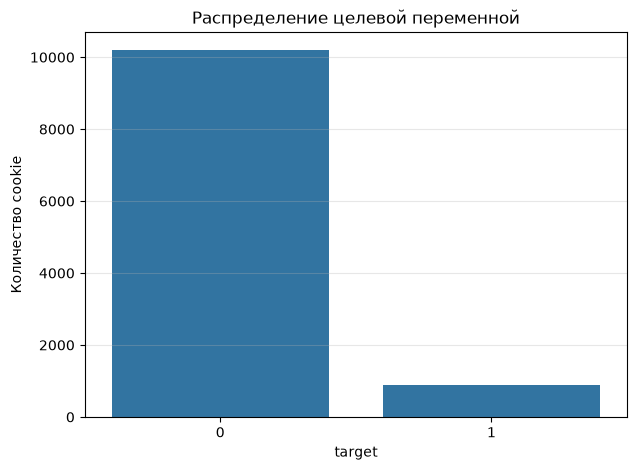

In [96]:
plt.figure(figsize=(7, 5))

sns.countplot(data=train, x="target",)

plt.title("Распределение целевой переменной")
plt.xlabel("target")
plt.ylabel("Количество cookie")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [97]:
positive_share = train["target"].mean()

print(f"Доля положительного класса: {positive_share:.4%}")

Доля положительного класса: 8.1057%


### Структура таблицы событий

Количество уникальных cookies.

In [98]:
print(f"Уникальных cookie_id в events: {events['cookie_id'].nunique()}")

Уникальных cookie_id в events: 16000


Количество событий на один cookie.

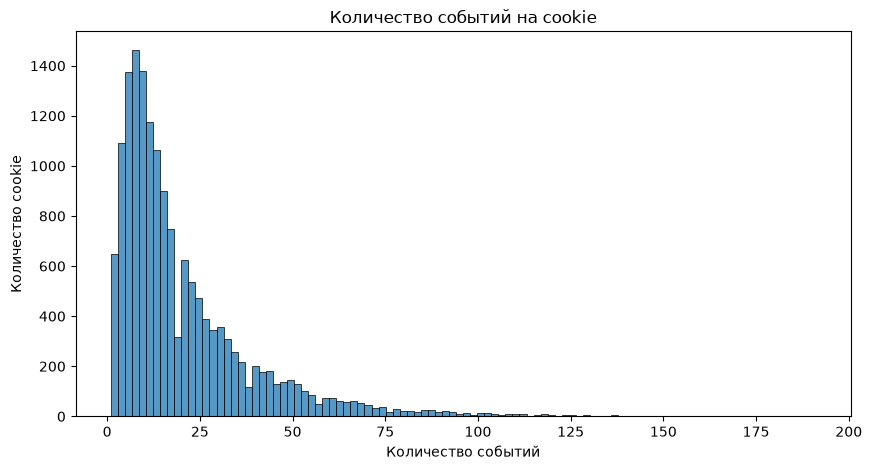

In [99]:
events_per_cookie = events.groupby("cookie_id").size()

plt.figure(figsize=(10, 5))

sns.histplot(events_per_cookie, bins=100)

plt.title("Количество событий на cookie")
plt.xlabel("Количество событий")
plt.ylabel("Количество cookie")

plt.show()

### Типы событий

In [100]:
event_name_counts = events["event_name"].value_counts().reset_index(name="count")

event_name_counts = event_name_counts.sort_values(by="count", ascending=False)

display(event_name_counts)

,event_name,count
0,item_view,120817
1,search_results_view,100402
2,photo_swipe,36517
3,favorite_add,19049
4,seller_page_view,17403
5,contact_phone_show,11316
6,captcha_shown,7928
7,login,6267
8,contact_chat_open,6125
9,contact_message_sent,3081


Всего в выборке присутствует 10 различных типов событий

### Пропуски в событиях

In [101]:
print(events.isna().sum())

cookie_id             0
event_ts              0
eid                   0
event_name            0
platform              0
user_agent            0
item_id          114597
item_category     32920
item_location     23793
seller_type      133853
search_query     228503
search_page      228503
pointer_x        220365
pointer_y        220365
dtype: int64


## Формирование допустимого набора событий

### Проверка событий вне окна наблюдения

Для каждого события необходимо определить, попадает ли его временная метка `event_ts` в окно наблюдения соответствующей cookie.

In [102]:
train_window_info = train[["cookie_id", "window_start_ts", "window_end_ts"]].copy()

test_window_info = test[["cookie_id", "window_start_ts", "window_end_ts",]].copy()

window_info = pd.concat([train_window_info, test_window_info], ignore_index=True)

print(f"Размер датафрейма window_info: {window_info.shape}")

Размер датафрейма window_info: (16000, 3)


In [103]:
events_with_window = events.merge(
    window_info,
    on="cookie_id",
    how="left",
    validate="many_to_one",
)

print(f"Событий после присоединения временных границ: {len(events_with_window)}")

Событий после присоединения временных границ: 328905


In [104]:
events_with_window.head(3)

,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y,window_start_ts,window_end_ts
0,ck_5efbea1befdefe1b,2026-04-26 09:11:24,200,item_view,desktop,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1027450.0,elektronika,kaliningrad,pro,NaN,NaN,NaN,NaN,2026-04-26,2026-04-27
1,ck_c4ca1434f3778f1d,2026-04-20 14:04:31,100,search_results_view,web,Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...,NaN,telefony,habarovsk,NaN,iphone 13 128,4.0,NaN,NaN,2026-04-20,2026-04-21
2,ck_d274382b19488771,2026-04-13 12:02:56,200,item_view,WEB,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0,2026-04-13,2026-04-14


In [105]:
events_before_window = (events_with_window["event_ts"] < events_with_window["window_start_ts"])
events_after_window = (events_with_window["event_ts"] >= events_with_window["window_end_ts"])
events_inside_window = (~events_before_window & ~events_after_window)

In [106]:
print(f"Событий до начала окна: {events_before_window.sum()}")
print(f"Событий внутри окна: {events_inside_window.sum()}")
print(f"Событий после окончания окна: {events_after_window.sum()}")

Событий до начала окна: 0
Событий внутри окна: 288126
Событий после окончания окна: 40779


Оставляем только события, которые попали в суточное окно наблюдения.

In [107]:
valid_event_mask = (
    (events_with_window["event_ts"] >= events_with_window["window_start_ts"])
    & (events_with_window["event_ts"] < events_with_window["window_end_ts"])
)

valid_events = events_with_window.loc[valid_event_mask].copy()

print(f"Размер датафрейма валидных событий: {valid_events.shape}")

Размер датафрейма валидных событий: (288126, 16)


## Исследование поведения пользователей

In [108]:
QUANTILES = [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

QUANTILE_LABELS = ["25%", "50%", "75%", "90%", "95%", "99%"]

### Общая активность cookie

In [109]:
events_per_cookie = valid_events.groupby("cookie_id").size().rename("event_count")

print("Число событий на каждый cookie за окно наблюдения:")
display(events_per_cookie)

Число событий на каждый cookie за окно наблюдения:


cookie_id
ck_00013fdfa0bd37dd    15
ck_000c95f1408dcb00    16
ck_000e8c52636e3bec    34
ck_0010e31baa4a1fb7    16
ck_0010ec3874fb5378    74
                       ..
ck_ffee36a37e2532f5    81
ck_fff88a7920fd0fb6    11
ck_fff9fdc2adf5100b    37
ck_fffa0622344a36ab    11
ck_fffa4b3ab0203fcf    41
Name: event_count, Length: 16000, dtype: int64

In [110]:
events_with_target = valid_events.merge(train[["cookie_id", "target"]], on="cookie_id", how="inner")

Добавляем метку класса.

In [111]:
cookie_activity = (
    train[["cookie_id", "target"]]
    .merge(
        events_per_cookie,
        on="cookie_id",
        how="left"
    )
)

cookie_activity.sample(3, random_state=RANDOM_STATE)

,cookie_id,target,event_count
1891,ck_8df0e1700243310f,0,31
9165,ck_4d70e8e03b078415,0,7
3902,ck_eebaaa38fb01fa72,0,23


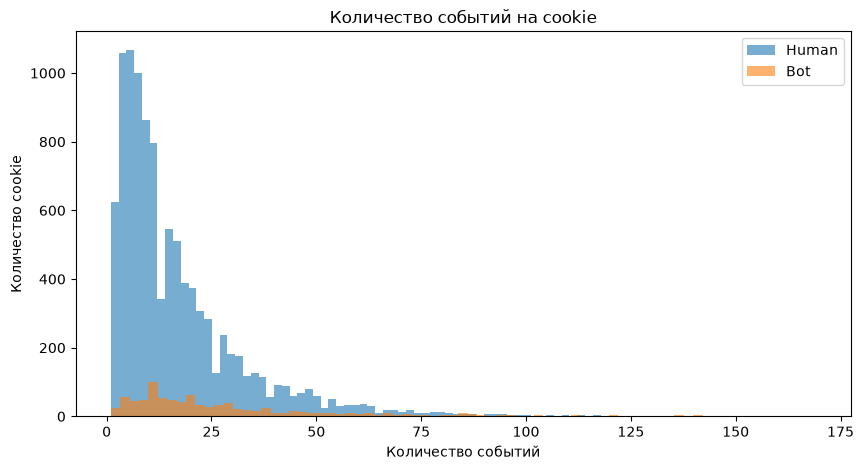

In [112]:
plt.figure(figsize=(10, 5))

for target, label in [(0, "Human"), (1, "Bot")]:
    values = cookie_activity.loc[cookie_activity["target"] == target, "event_count"]

    plt.hist(values, bins=75, alpha=0.6, label=label)

plt.xlabel("Количество событий")
plt.ylabel("Количество cookie")
plt.title("Количество событий на cookie")
plt.legend()
plt.show()

In [113]:
event_count_stats = cookie_activity.groupby("target")["event_count"]

In [114]:
display(event_count_stats.describe(percentiles=QUANTILES))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,10192.0,16.869015,16.173297,1.0,6.0,12.0,22.0,37.0,50.0,79.00,140.0
1,899.0,29.484983,27.515182,1.0,11.0,20.0,38.0,67.2,88.0,134.04,169.0


Боты в среднем генерируют больше событий, чем обычные пользователи: среднее количество событий составляет 29.49 против 16.88, медианное - 20 против 12.

### Частоты типов событий

Посмотрим, различается ли структура действий между людьми и ботами.

In [115]:
event_type_counts = events_with_target.groupby(["target", "event_name"]).size().rename("count").reset_index()

event_type_counts["share"] = (
    event_type_counts["count"]
    / event_type_counts.groupby("target")["count"].transform("sum")
)

display(event_type_counts)

,target,event_name,count,share
0,0,contact_chat_open,3404,0.019799
1,0,contact_message_sent,1769,0.010289
2,0,contact_phone_show,6361,0.036998
3,0,favorite_add,11317,0.065824
4,0,item_view,62770,0.365093
5,0,login,3693,0.021480
6,0,photo_swipe,21091,0.122673
7,0,search_results_view,52399,0.304771
8,0,seller_page_view,9125,0.053074
9,1,contact_chat_open,376,0.014185


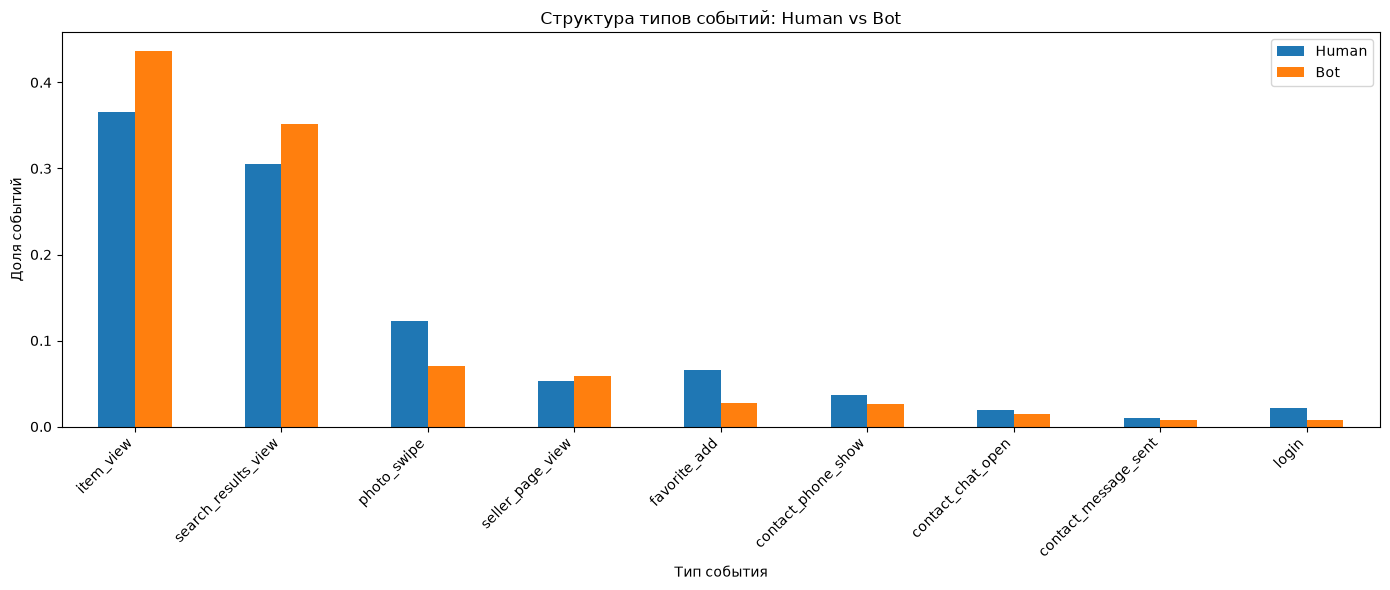

In [116]:
plot_data = (
    event_type_counts
    .pivot(index="event_name", columns="target", values="share")
    .rename(columns={0: "human_share", 1: "bot_share"})
    .sort_values("bot_share", ascending=False)
)

plot_data.plot(kind="bar", figsize=(14, 6))

plt.xlabel("Тип события")
plt.ylabel("Доля событий")
plt.title("Структура типов событий: Human vs Bot")
plt.xticks(rotation=45, ha="right")
plt.legend(["Human", "Bot"])
plt.tight_layout()
plt.show()

Анализ структуры событий показал различия в характере активности пользователей. В поведении ботов большую долю занимают просмотры объявлений и страниц результатов поиска. Одновременно у ботов существенно ниже доля событий, связанных с более глубоким взаимодействием с интерфейсом. Таким образом, классы отличаются не только общей интенсивностью, но и структурой выполняемых действий.

### Временная активность

In [117]:
events_with_hour = events_with_target.copy()
events_with_hour["hour"] = events_with_hour["event_ts"].dt.hour

hour_activity = (
    events_with_hour
    .groupby(["target", "hour"])
    .size()
    .reset_index(name="event_count")
)

hour_activity["share"] = (
    hour_activity["event_count"]
    / hour_activity.groupby("target")["event_count"].transform("sum")
)

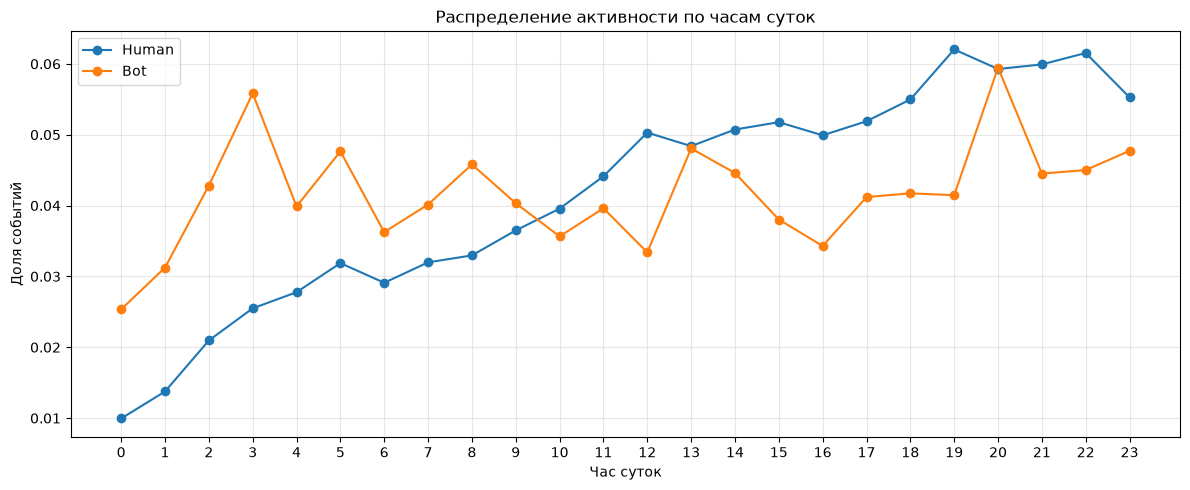

In [118]:
hour_plot = hour_activity.pivot(index="hour", columns="target", values="share")

hour_plot.plot(figsize=(12, 5), marker="o")

plt.xlabel("Час суток")
plt.ylabel("Доля событий")
plt.title("Распределение активности по часам суток")
plt.xticks(range(24))
plt.legend(["Human", "Bot"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Анализ временной активности показал различия между классами. У обычных пользователей наблюдается выраженный суточный профиль с минимальной активностью в ночные часы и постепенным увеличением активности в течение дня с максимумом в вечернее время. У ботов распределение активности более неравномерное: доля событий в ночные часы существенно выше, а максимальные значения наблюдаются, в частности, около 03:00 и 20:00. Это может быть связано со сбросом каких-либо лимитов на запросы к серверу.

### Интервалы между событиями

Предположительно боты действуют интенсивнее людей. Проверим это.

In [119]:
events_with_intervals = events_with_target.sort_values(["cookie_id", "event_ts"]).copy()

events_with_intervals["delta_seconds"] = events_with_intervals.groupby("cookie_id")["event_ts"].diff().dt.total_seconds()

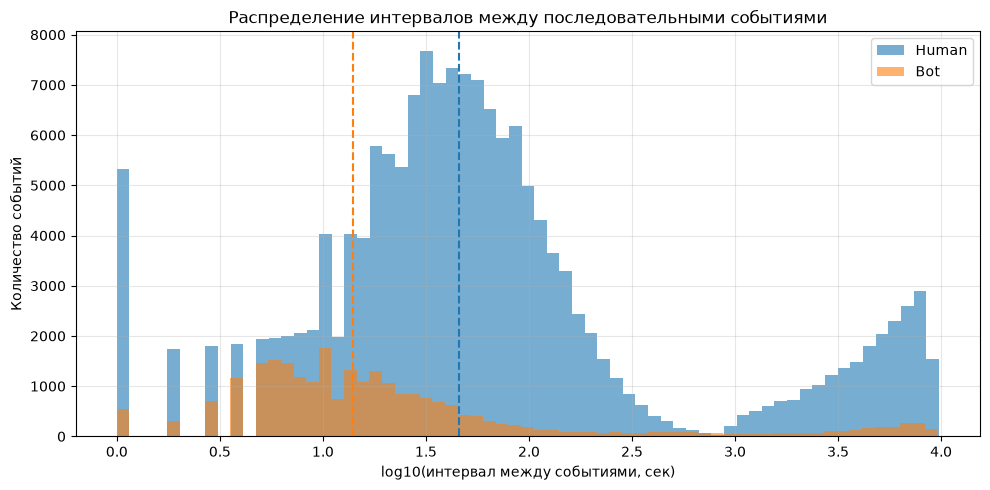

In [120]:
plot_data = events_with_intervals.dropna(subset=["delta_seconds"])

plt.figure(figsize=(10, 5))

for target, label in [(0, "Human"), (1, "Bot")]:
    values = plot_data.loc[plot_data["target"] == target, "delta_seconds"]
    plt.hist(
        np.log10(values.clip(lower=1)),
        bins=65,
        alpha=0.6,
        label=label,
    )

medians = plot_data.groupby("target")["delta_seconds"].median()

for target, color in [(0, "C0"), (1, "C1")]:
    plt.axvline(
        np.log10(medians[target]),
        color=color,
        linestyle="--",
        linewidth=1.5,
        alpha=1,
    )

plt.xlabel("log10(интервал между событиями, сек)")
plt.ylabel("Количество событий")
plt.title("Распределение интервалов между последовательными событиями")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [121]:
display(
    events_with_intervals
    .dropna(subset=["delta_seconds"])
    .groupby("target")["delta_seconds"]
    .describe(percentiles=QUANTILES)
)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,161737.0,732.349722,1892.005365,0.0,19.0,46.0,117.0,3107.0,5997.0,8445.0,9760.0
1,25608.0,424.182990,1478.952700,0.0,7.0,14.0,35.0,372.3,3930.6,7947.3,9608.0


Анализ интервалов между последовательными событиями выявил существенные различия в темпе активности. Медианный интервал у ботов составляет 14 секунд, тогда как у обычных пользователей - 46 секунд. Аналогичное различие наблюдается и в других частях распределения: 25-й перцентиль составляет 7 и 19 секунд, а 75-й - 35 и 117 секунд соответственно.

### Поисковое поведение

Отдельно смотрим, сколько раз каждая cookie просматривала страницу результатов поиска.

In [122]:
search_events = events_with_target[events_with_target["event_name"] == "search_results_view"]

search_activity = search_events.groupby(["target", "cookie_id"]).size().rename("search_count").reset_index()

display(search_activity.groupby("target")["search_count"].describe(percentiles=QUANTILES))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,9308.0,5.629459,5.191374,1.0,2.0,4.0,7.0,12.0,16.0,25.0,45.0
1,862.0,10.809745,11.060744,1.0,3.0,7.0,14.0,26.0,33.0,53.0,66.0


Боты активнее пользуются поиском, чем люди. Медиана и среднее значение числа поисковых запросов на одну cookie различается практически в два раза.

### Работа с объявлениями

Из прошлых разделов удалось установить, что самое частое событие у ботов - item_view. Оценим, сколько объявлений смотрит отдельная cookie, сколько из них уникальны.

Общее число просмотренных объявлений.

In [123]:
item_events = events_with_target[events_with_target["event_name"] == "item_view"]

item_views = item_events.groupby(["target", "cookie_id"]).size().rename("item_view_count").reset_index()

display(item_views.groupby("target")["item_view_count"].describe(percentiles=QUANTILES))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,9479.0,6.622007,6.134136,1.0,2.0,5.0,9.0,15.0,19.0,29.00,55.0
1,883.0,13.100793,13.399074,1.0,4.0,8.0,16.0,31.0,43.9,61.18,91.0


Число уникальных просмотренных объявлений.

In [124]:
unique_items = item_events.groupby(["target", "cookie_id"])["item_id"].nunique().rename("unique_item_count").reset_index()

display(unique_items.groupby("target")["unique_item_count"].describe(percentiles=QUANTILES))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,9479.0,5.703766,5.295351,1.0,2.0,4.0,7.0,12.0,17.0,26.0,43.0
1,883.0,10.160815,9.071970,1.0,4.0,7.0,13.0,23.8,29.0,41.0,61.0


Боты взаимодействуют с заметно большим числом объявлений. Медианное число просмотров составляет 5 у пользователей и 8 у ботов, а медианное число уникальных объявлений - 4 у пользователей и 7 у ботов. Разрыв сохраняется и растет к хвосту распределения: на 95-м перцентиле пользователи просматривают 19 объявлений, а боты - 44.

### Работа со страницами продавцов

Смотрим, как часто cookie открывает страницу продавца.

Число просмотров страниц продавца.

In [125]:
seller_events = events_with_target[events_with_target["event_name"] == "seller_page_view"]

seller_views = seller_events.groupby(["target", "cookie_id"]).size().rename("seller_page_view_count").reset_index()

display(seller_views.groupby("target")["seller_page_view_count"].describe(percentiles=QUANTILES))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,5043.0,1.809439,1.231276,1.0,1.0,1.0,2.0,3.0,4.0,6.0,11.0
1,608.0,2.570724,1.877184,1.0,1.0,2.0,3.0,5.0,6.0,9.0,14.0


Доля cookie, которые никогда не открывали страницу продавца.

In [126]:
sellers_per_cookie = seller_events.groupby("target")["cookie_id"].nunique()

total_per_target = events_with_target.groupby("target")["cookie_id"].nunique()

display(sellers_per_cookie / total_per_target)

target
0    0.494800
1    0.676307
Name: cookie_id, dtype: float64

Боты чаще взаимодействуют со страницами продавцов. Медианное число просмотров составляет 2 против 1 у пользователей, а на 90-м процентиле - 5 против 3. Кроме того, событие seller_page_view зафиксировано хотя бы один раз у 67.6% ботов и 49.5% пользователей.

### Контактные действия

Число контактных действий на cookie.

In [127]:
contact_event_names = ["contact_message_sent", "contact_chat_open", "contact_phone_show"]

contact_events = events_with_target[events_with_target["event_name"].isin(contact_event_names)]

contact_activity = contact_events.groupby(["target", "cookie_id"]).size().rename("contact_action_count").reset_index()

display(contact_activity.groupby("target")["contact_action_count"].describe(percentiles=QUANTILES))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,4930.0,2.339554,2.203006,1.0,1.0,1.0,3.0,5.0,7.0,11.0,19.0
1,467.0,2.721627,2.829873,1.0,1.0,2.0,3.0,6.0,8.0,15.0,22.0


In [128]:
contacted_per_target = contact_events.groupby("target")["cookie_id"].nunique()

display(contacted_per_target / total_per_target)

target
0    0.483713
1    0.519466
Name: cookie_id, dtype: float64

Контактные действия встречаются примерно у половины cookie обоих классов (48.4% у пользователей против 51.9% у ботов), а по интенсивности различаются слабо - медиана 1 против 2 (абсолютные значения достаточно малы).

### Избранное и авторизация

Добавления в избранное.

In [129]:
favorite_events = events_with_target[events_with_target["event_name"] == "favorite_add"]

favorite_activity = favorite_events.groupby(["target", "cookie_id"]).size().rename("favorite_count").reset_index()

display(favorite_activity.groupby("target")["favorite_count"].describe(percentiles=QUANTILES))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,5582.0,2.02741,1.478073,1.0,1.0,2.0,3.0,4.0,5.0,7.19,13.0
1,403.0,1.78660,1.280982,1.0,1.0,1.0,2.0,3.0,4.0,7.00,9.0


Доля cookie, которые хотя бы раз добавляли в избранное.

In [130]:
favorited_per_target = favorite_events.groupby("target")["cookie_id"].nunique()

display(favorited_per_target / total_per_target)

target
0    0.547684
1    0.448276
Name: cookie_id, dtype: float64

Авторизация

In [131]:
login_events = events_with_target[events_with_target["event_name"] == "login"]

login_activity = login_events.groupby(["target", "cookie_id"]).size().rename("login_count").reset_index()

display(login_activity.groupby("target")["login_count"].describe(percentiles=QUANTILES))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,2740.0,1.347810,0.670545,1.0,1.0,1.0,2.0,2.0,3.0,4.0,6.0
1,173.0,1.196532,0.490123,1.0,1.0,1.0,1.0,2.0,2.0,3.0,4.0


Доля cookie, которые хотя бы раз авторизовались.

In [132]:
logged_in_per_target = login_events.groupby("target")["cookie_id"].nunique()

display(logged_in_per_target / total_per_target)

target
0    0.268838
1    0.192436
Name: cookie_id, dtype: float64

Пользователи чаще используют функции, связанные с сохранением объявлений и авторизацией. Добавление в избранное встречается у 54.8% пользователей против 44.9% ботов, а авторизация - у 26.9% против 19.2%. При этом среди cookie, совершавших эти действия, количество операций между классами различается незначительно.

### Работа с капчей

Посмотрим на статистику по срабатыванию защитного механизма - капчи.

In [133]:
captcha_events = events_with_target[events_with_target["event_name"] == "captcha_shown"]

captcha_activity = captcha_events.groupby(["target", "cookie_id"]).size().rename("captcha_count").reset_index()

display(captcha_activity)

,target,cookie_id,captcha_count


Событие captcha_shown практически отсутствует в данных: оно наблюдается только у двух cookie, обе относятся к классу ботов. Из-за крайне малого числа наблюдений данный признак не представляет интереса для дальнейшего анализа.

### Поведение указателя мыши

Живые пользователи всегда используют мышь для навигации по сайту, а для ботов указатель не нужен. Например, скрипты, написанные на Selenium могут взаимодействовать с сайтом, зацепившись за конкретные html теги.

Доля событий с координатами мыши.

In [134]:
events_with_target["has_pointer"] = (events_with_target["pointer_x"].notna() & events_with_target["pointer_y"].notna())

pointer_share = events_with_target.groupby("target")["has_pointer"].mean().rename("pointer_share")

display(pointer_share)

target
0    0.347376
1    0.245935
Name: pointer_share, dtype: float64

In [135]:
pointer_events = events_with_target[events_with_target["pointer_x"].notna() & events_with_target["pointer_y"].notna()]

pointer_activity = pointer_events.groupby(["target", "cookie_id"]).size().rename("pointer_event_count").reset_index()

display(pointer_activity.groupby("target")["pointer_event_count"].describe(percentiles=QUANTILES))

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
target,,,,,,,,,,,
0,3795.0,15.737549,15.526234,1.0,6.0,11.0,20.0,35.0,47.0,76.0,128.0
1,251.0,25.972112,24.244488,1.0,10.0,19.0,31.0,57.0,84.0,116.0,135.0


In [136]:
pointer_cookies = pointer_events.groupby("target")["cookie_id"].nunique()

display(pointer_cookies / total_per_target)

target
0    0.372351
1    0.279199
Name: cookie_id, dtype: float64

Доля событий с координатами мыши у людей выше - 34.7% против 24.6% у ботов.

### Платформа и юзер-агент

In [137]:
display(events_with_target["platform"].value_counts(dropna=False))

platform
desktop    27855
Web        27470
WEB        27431
web        27251
ANDROID    26209
Android    25893
android    25889
IOS         2634
iOS         2626
iphone      2602
ios         2576
Name: count, dtype: int64

In [138]:
events_with_target["platform_norm"] = events_with_target["platform"].str.lower().str.strip()

Распределение платформы по классам.

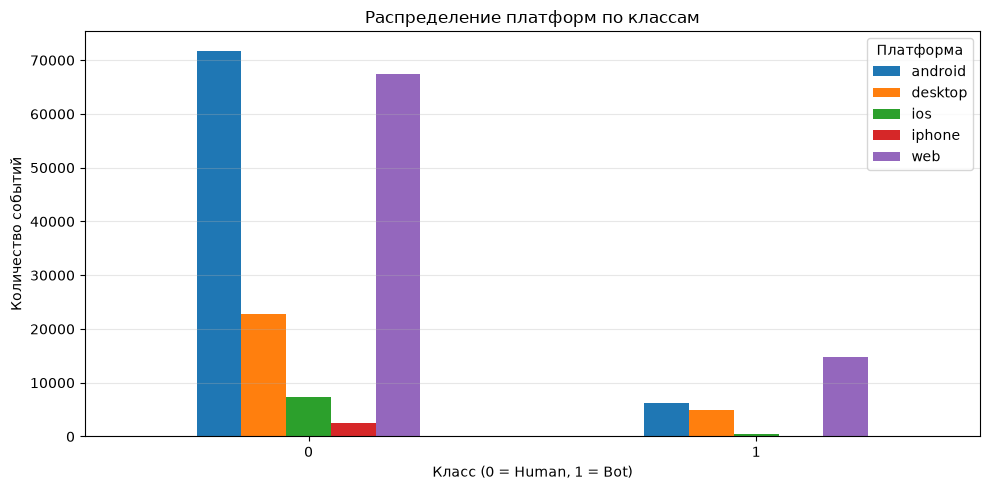

In [139]:
platform_by_events = events_with_target.groupby(["target", "platform_norm"]).size().unstack(fill_value=0)

platform_by_events.plot(kind="bar", figsize=(10, 5),rot=0)

plt.xlabel("Класс (0 = Human, 1 = Bot)")
plt.ylabel("Количество событий")
plt.title("Распределение платформ по классам")
plt.legend(title="Платформа")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Доли платформ внутри класса.

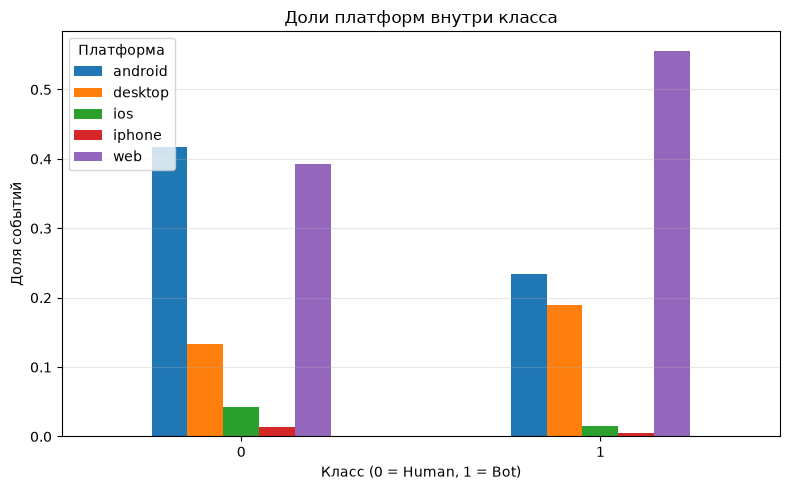

In [140]:
platform_share = platform_by_events.div(platform_by_events.sum(axis=1), axis=0)

platform_share.plot(kind="bar", stacked=False, figsize=(8, 5),rot=0)

plt.xlabel("Класс (0 = Human, 1 = Bot)")
plt.ylabel("Доля событий")
plt.title("Доли платформ внутри класса")
plt.legend(title="Платформа", loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Построение признаков

In [141]:
valid_events["platform_norm"] = valid_events["platform"].str.lower().str.strip()
valid_events = valid_events.drop(columns=["platform"])
valid_events = valid_events.rename(columns={"platform_norm": "platform"})

In [142]:
valid_events_train = valid_events[valid_events["cookie_id"].isin(train["cookie_id"])].copy()
valid_events_test  = valid_events[valid_events["cookie_id"].isin(test["cookie_id"])].copy()

valid_events_train = valid_events_train.sort_values(["cookie_id", "event_ts"]).reset_index(drop=True)
valid_events_test  = valid_events_test.sort_values(["cookie_id", "event_ts"]).reset_index(drop=True)

print(f"Размер датафрейма событий для обучающей выборки: {valid_events_train.shape}")
print(f"Размер датафрейма событий для тестовой выборки: {valid_events_test.shape}")

Размер датафрейма событий для обучающей выборки: (198436, 16)
Размер датафрейма событий для тестовой выборки: (89690, 16)


In [143]:
def get_event_types(valid_events: pd.DataFrame) -> list[str]:
    """
    Возвращает отсортированный список уникальных типов событий.
    Используется на обучающей выборке, чтобы зафиксировать схему признаков.
    """
    return sorted(valid_events["event_name"].unique().tolist())

In [144]:
def build_event_type_features(
    valid_events: pd.DataFrame,
    event_types: list[str],
) -> pd.DataFrame:
    """
    Строит счетчики по типам событий с фиксированной схемой колонок.
    """
    events_cat = valid_events[["cookie_id", "event_name"]].copy()
    events_cat["event_name"] = pd.Categorical(
        events_cat["event_name"],
        categories=event_types,
    )

    event_name_dummies = pd.get_dummies(
        events_cat,
        columns=["event_name"],
        prefix="event",
    )

    event_type_counts = (
        event_name_dummies.groupby("cookie_id")
        .sum()
        .astype(int)
        .rename(columns=lambda col: f"{col}_count")
    )

    return event_type_counts.reset_index()

In [145]:
PLATFORM_CODE = {
    "web": 0,
    "desktop": 1,
    "android": 2,
    "ios": 3,
}

In [146]:
BOT_UA_PATTERNS = [
    "python-requests",
    "python-urllib",
    "curl/",
    "wget/",
    "scrapy",
    "headlesschrome",
    "phantomjs",
    "selenium",
    "httpie",
    "aiohttp",
    "go-http-client",
    "okhttp",
    "libwww-perl",
    "java/",
    "apache-httpclient",
]

In [147]:
UA_PATTERNS = {
    "headless":   r"headless",
    "python":     r"python|requests|urllib",
    "scrapy":     r"scrapy",
    "curl":       r"curl",
    "wget":       r"wget",
    "node":       r"node-fetch|node/|axios",
    "go":         r"go-http-client",
    "java":       r"java/|apache-httpclient|okhttp",
    "selenium":   r"selenium|webdriver|phantom",
    "aiohttp":    r"aiohttp",
    "bot_word":   r"bot|spider|crawler",
    "http_lib":   r"httpie|libwww-perl|mechanize",
}

In [148]:
def build_features(
    valid_events: pd.DataFrame,
    cookie_meta: pd.DataFrame,
    event_types: list[str],
) -> pd.DataFrame:
    """
    Строит набор признаков на уровне cookie_id на основе событий,
    попавших в окно наблюдения.
    """
    
    features = cookie_meta[["cookie_id", "cookie_created_at", "window_start_ts", "window_end_ts"]].copy()

    grouped = valid_events.groupby("cookie_id")

    # Общее число событий на одну cookie
    event_counts = grouped.size().rename("total_events")
    features = features.merge(
        event_counts,
        on="cookie_id",
        how="left"
    )
    features["total_events"] = features["total_events"].fillna(0).astype(int)

    # Возраст cookie в днях на момент начала окна наблюдения
    features["cookie_age_days"] = (features["window_start_ts"] - features["cookie_created_at"]).dt.days

    # Число уникальных типов событий
    unique_event_types = grouped["event_name"].nunique().rename("unique_event_types")
    features = features.merge(unique_event_types, on="cookie_id", how="left")
    features["unique_event_types"] = features["unique_event_types"].fillna(0).astype(int)

    # Число уникальных платформ
    unique_platforms = grouped["platform"].nunique().rename("unique_platforms")
    features = features.merge(unique_platforms, on="cookie_id", how="left")
    features["unique_platforms"] = features["unique_platforms"].fillna(0).astype(int)

    # Разность между последним и первым событием в секундах 
    session_span = grouped["event_ts"].agg(lambda x: (x.max() - x.min()).total_seconds()).rename("session_span_seconds")
    features = features.merge(session_span, on="cookie_id", how="left")
    features["session_span_seconds"] = features["session_span_seconds"].fillna(0)

    # Статистики интервалов между событиями в рамках одного cookie
    delta_seconds = grouped["event_ts"].diff().dt.total_seconds()
    delta_agg = (
        valid_events.assign(delta_seconds=delta_seconds)
        .groupby("cookie_id")["delta_seconds"]
        .agg(
            mean_delta_seconds="mean",
            median_delta_seconds="median",
            min_delta_seconds="min",
            std_delta_seconds="std",
        )
    )
    features = features.merge(delta_agg, on="cookie_id", how="left")
    delta_cols = [
        "mean_delta_seconds",
        "median_delta_seconds",
        "min_delta_seconds",
        "std_delta_seconds",
    ]
    for col in delta_cols:
        features[col] = features[col].fillna(0)

    # Счетчики на каждый тип событий
    event_type_counts = build_event_type_features(valid_events, event_types)
    features = features.merge(event_type_counts, on="cookie_id", how="left")
    event_type_count_cols = [f"event_{et}_count" for et in event_types]
    features[event_type_count_cols] = (features[event_type_count_cols].fillna(0).astype(int))

    # Доля по каждому типу события
    total_events_safe = features["total_events"].replace(0, 1)
    for count_col in event_type_count_cols:
        share_col = count_col.replace("_count", "_share")
        features[share_col] = features[count_col] / total_events_safe

    # Число уникальных часов активности
    valid_events_hours = valid_events.assign(hour=valid_events["event_ts"].dt.hour).copy()
    unique_hours = valid_events_hours.groupby("cookie_id")["hour"].nunique().rename("unique_hours")
    features = features.merge(unique_hours, on="cookie_id", how="left")
    features["unique_hours"] = features["unique_hours"].fillna(0).astype(int)
    
    # Доля событий в ночное время суток
    valid_events_hours["is_night"] = valid_events_hours["hour"] < 6
    night_counts = valid_events_hours.groupby("cookie_id")["is_night"].sum().rename("night_event_count")
    features = features.merge(night_counts, on="cookie_id", how="left")
    features["night_event_count"] = features["night_event_count"].fillna(0)
    features["night_event_share"] = features["night_event_count"] / total_events_safe

    # Доля событий в утреннее время суток
    valid_events_hours["is_morning"] = (valid_events_hours["hour"] >= 6) & (valid_events_hours["hour"] < 12)
    morning_counts = valid_events_hours.groupby("cookie_id")["is_morning"].sum().rename("morning_event_count")
    features = features.merge(morning_counts, on="cookie_id", how="left")
    features["morning_event_count"] = features["morning_event_count"].fillna(0)
    features["morning_event_share"] = features["morning_event_count"] / total_events_safe

    # Разброс активности (разность между максимальным и минимальным часов активности cookie)
    hours_span = valid_events_hours.groupby("cookie_id")["hour"].agg(lambda x: x.max() - x.min() + 1).rename("active_hours_span")
    features = features.merge(hours_span, on="cookie_id", how="left")
    features["active_hours_span"] = features["active_hours_span"].fillna(0).astype(int)

    search_events = valid_events[valid_events["event_name"] == "search_results_view"].sort_values(["cookie_id", "event_ts"]).copy()

    # Число уникальных поисковых запросов
    unique_search_queries = search_events.groupby("cookie_id")["search_query"].nunique().rename("unique_search_queries")
    features = features.merge(unique_search_queries, on="cookie_id", how="left")
    features["unique_search_queries"] = features["unique_search_queries"].fillna(0).astype(int)

    # Доля поисковых действий на новые запросы
    search_events_count_safe = features["event_search_results_view_count"].replace(0, 1)
    features["queries_per_search_event"] = features["unique_search_queries"] / search_events_count_safe

    # Средний номер страницы просмотра результатов поискового запроса
    mean_search_page = search_events.groupby("cookie_id")["search_page"].mean().rename("mean_search_page")
    features = features.merge(mean_search_page, on="cookie_id", how="left")
    features["mean_search_page"] = features["mean_search_page"].fillna(0)

    # Максимальный номер страницы просмотра результатов поискового запроса
    max_search_page = search_events.groupby("cookie_id")["search_page"].max().rename("max_search_page")
    features = features.merge(max_search_page, on="cookie_id", how="left")
    features["max_search_page"] = features["max_search_page"].fillna(0)

    # Статистики интервалов между последовательными поисковыми запросами
    search_delta_seconds = search_events.groupby("cookie_id")["event_ts"].diff().dt.total_seconds()
    search_delta_agg = (
        search_events.assign(delta_seconds=search_delta_seconds)
        .groupby("cookie_id")["delta_seconds"]
        .agg(
            mean_search_interval_seconds="mean",
            median_search_interval_seconds="median",
            std_search_interval_seconds="std",
        )
    )
    features = features.merge(search_delta_agg, on="cookie_id", how="left")
    search_delta_cols = [
        "mean_search_interval_seconds",
        "median_search_interval_seconds",
        "std_search_interval_seconds",
    ]
    for col in search_delta_cols:
        features[col] = features[col].fillna(0)

    # Число уникальных просмотренных объявлений
    item_view_events = valid_events[valid_events["event_name"] == "item_view"].sort_values(["cookie_id", "event_ts"]).copy()
    unique_items_viewed = item_view_events.groupby("cookie_id")["item_id"].nunique().rename("unique_items_viewed")
    features = features.merge(unique_items_viewed, on="cookie_id", how="left")
    features["unique_items_viewed"] = features["unique_items_viewed"].fillna(0).astype(int)

    # Доля просмотров, которая приходится на новые объявления
    item_view_count_safe = features["event_item_view_count"].replace(0, 1)
    features["items_per_item_view"] = features["unique_items_viewed"] / item_view_count_safe

    # Уникальное число просмотренных категорий
    unique_categories_viewed = item_view_events.groupby("cookie_id")["item_category"].nunique().rename("unique_categories_viewed")
    features = features.merge(unique_categories_viewed, on="cookie_id", how="left")
    features["unique_categories_viewed"] = features["unique_categories_viewed"].fillna(0).astype(int)

    # Число уникальных локаций в просмотренных объявлениях
    unique_locations_viewed = item_view_events.groupby("cookie_id")["item_location"].nunique().rename("unique_locations_viewed")
    features = features.merge(unique_locations_viewed, on="cookie_id", how="left")
    features["unique_locations_viewed"] = features["unique_locations_viewed"].fillna(0).astype(int)

    # Доля доминирующей категории среди просмотренных объявлений
    category_events = item_view_events.dropna(subset=["item_category"]).groupby(["cookie_id", "item_category"]).size().rename("count")
    category_total = category_events.groupby("cookie_id").sum()
    category_top = category_events.groupby("cookie_id").max()
    top_category_share = (category_top / category_total).rename("top_category_share")
    features = features.merge(top_category_share.reset_index(), on="cookie_id", how="left")
    features["top_category_share"] = features["top_category_share"].fillna(0)

    # Доля доминирующей локации среди просмотренных объявлений
    location_events = item_view_events.dropna(subset=["item_location"]).groupby(["cookie_id", "item_location"]).size().rename("count")
    location_total = location_events.groupby("cookie_id").sum()
    location_top = location_events.groupby("cookie_id").max()
    top_location_share = (location_top / location_total).rename("top_location_share")
    features = features.merge(top_location_share.reset_index(), on="cookie_id", how="left")
    features["top_location_share"] = features["top_location_share"].fillna(0)

    # Просматривалась ли страница продавца хотя бы раз
    features["has_seller_view"] = (features["event_seller_page_view_count"] > 0).astype(int)

    # Было ли взаимодействие любого типа (запрос телефона, отправленное сообщение, открытый чай)
    contact_event_count_cols = ["event_contact_phone_show_count", "event_contact_chat_open_count", "event_contact_message_sent_count"]
    features["contact_events_count"] = features[contact_event_count_cols].sum(axis=1)
    features["has_any_contact"] = (features["contact_events_count"] > 0).astype(int)

    # Доля контактных действия от общего числа событий
    features["contact_share_of_events"] = features["contact_events_count"] / total_events_safe

    # Число событий с зафиксированными координатами мыши
    pointer_events = valid_events[valid_events["pointer_x"].notna() & valid_events["pointer_y"].notna()].copy()
    pointer_events_count = (pointer_events.groupby("cookie_id").size().rename("pointer_events_count"))
    features = features.merge(pointer_events_count, on="cookie_id", how="left")
    features["pointer_events_count"] = features["pointer_events_count"].fillna(0).astype(int)

    # Флаг наличия событий с мышью
    features["has_pointer_events"] = (features["pointer_events_count"] > 0).astype(int)

    # Доля событий с зафиксированными координатами мыши
    features["pointer_events_share"] = features["pointer_events_count"] / total_events_safe

    # Средние смещения курсора по вертикали и горизонтали
    pointer_events = pointer_events.sort_values(["cookie_id", "event_ts"])
    pointer_dx = pointer_events.groupby("cookie_id")["pointer_x"].diff().abs()
    pointer_dy = pointer_events.groupby("cookie_id")["pointer_y"].diff().abs()
    pointer_delta_agg = (
        pointer_events.assign(dx=pointer_dx, dy=pointer_dy)
        .groupby("cookie_id")
        .agg(
            mean_pointer_dx=("dx", "mean"),
            mean_pointer_dy=("dy", "mean"),
        )
    )
    features = features.merge(pointer_delta_agg, on="cookie_id", how="left")
    features["mean_pointer_dx"] = features["mean_pointer_dx"].fillna(0)
    features["mean_pointer_dy"] = features["mean_pointer_dy"].fillna(0)

    # Самая популярная платформа отдельного cookie
    platform_mode = valid_events.groupby("cookie_id")["platform"].agg(lambda x: x.value_counts().index[0]).rename("platform_mode")
    features = features.merge(platform_mode, on="cookie_id", how="left")
    features["platform_code"] = features["platform_mode"].map(PLATFORM_CODE).fillna(-1).astype(int)
    features = features.drop(columns=["platform_mode"])

    # Число уникальных юзер-агентов
    user_agent_count = grouped["user_agent"].nunique().rename("user_agent_count")
    features = features.merge(user_agent_count, on="cookie_id", how="left")
    features["user_agent_count"] = features["user_agent_count"].fillna(0).astype(int)

    # Юзер-агент
    valid_events_ua = valid_events.assign(ua_lower=valid_events["user_agent"].fillna("").str.lower())
    ua_features_list = []
    for name, pattern in UA_PATTERNS.items():
        is_match = valid_events_ua["ua_lower"].str.contains(pattern, regex=True, na=False)
        valid_events_ua[f"ua_{name}_flag"] = is_match

    ua_grouped = valid_events_ua.groupby("cookie_id")
    ua_flag_features = ua_grouped[[f"ua_{name}_flag" for name in UA_PATTERNS]].max()
    ua_flag_features.columns = [f"ua_{name}" for name in UA_PATTERNS]

    ua_event_features = ua_grouped[[f"ua_{name}_flag" for name in UA_PATTERNS]].sum()
    ua_event_features.columns = [f"ua_{name}_events" for name in UA_PATTERNS]

    total_events_safe_ua = features.set_index("cookie_id")["total_events"].reindex(ua_event_features.index).replace(0, 1)
    ua_share_features = ua_event_features.div(total_events_safe_ua, axis=0).fillna(0)
    ua_share_features.columns = [f"ua_{name}_share" for name in UA_PATTERNS]

    ua_all_features = pd.concat([ua_flag_features, ua_event_features, ua_share_features], axis=1).reset_index()
    features = features.merge(ua_all_features, on="cookie_id", how="left")

    ua_cols = [c for c in features.columns if c.startswith("ua_")]
    features[ua_cols] = features[ua_cols].fillna(0)


    features = features.drop(columns=["cookie_created_at", "window_start_ts", "window_end_ts", "night_event_count", "morning_event_count", "contact_events_count"])


    return features

In [149]:
event_types = get_event_types(valid_events_train)

train_features = build_features(valid_events_train, train, event_types)
test_features = build_features(valid_events_test, test, event_types)

display(test_features)

,cookie_id,total_events,cookie_age_days,unique_event_types,unique_platforms,session_span_seconds,mean_delta_seconds,median_delta_seconds,min_delta_seconds,std_delta_seconds,...,ua_scrapy_share,ua_curl_share,ua_wget_share,ua_node_share,ua_go_share,ua_java_share,ua_selenium_share,ua_aiohttp_share,ua_bot_word_share,ua_http_lib_share
0,ck_315fb710a0e371e7,80,58,8,2,43915.0,555.886076,41.0,0.0,1696.639756,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ck_a76ee3b3e3e522fd,9,90,5,2,189.0,23.625000,11.0,0.0,32.262041,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ck_94c9a4d382689e82,8,0,5,1,7214.0,1030.571429,65.0,18.0,2578.239894,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,ck_8eaf9509ad9462a0,9,90,3,2,571.0,71.375000,63.5,4.0,53.598874,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,ck_9a88a5a989cb5bc6,2,161,2,1,80.0,80.000000,80.0,80.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4904,ck_8b772caed8f1541c,2,50,1,1,8972.0,8972.000000,8972.0,8972.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4905,ck_5403c76fe68a08ba,22,221,4,1,6565.0,312.619048,23.0,5.0,1039.914539,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4906,ck_3e6833574edf1736,9,78,6,2,13355.0,1669.375000,205.0,23.0,3219.688625,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4907,ck_e527fbb9450a4581,17,0,4,2,7520.0,470.000000,18.0,3.0,1301.005355,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Формирование обучающей и валидационной выборок

### Формирование матрицы признаков

In [150]:
train_dataset = train[["cookie_id", "target", "window_start_ts"]].merge(
    train_features,
    on="cookie_id",
    how="left",
    validate="one_to_one",
)

test_dataset = test_features.copy()

print(f"Размерность обучающего датасета: {train_dataset.shape}")
print(f"Размерность тренировочного датасета: {test_dataset.shape}")

Размерность обучающего датасета: (11091, 93)
Размерность тренировочного датасета: (4909, 91)


In [151]:
feature_cols = [c for c in train_dataset.columns if c not in ("cookie_id", "target", "window_start_ts")]
X = train_dataset[feature_cols].copy()
y = train_dataset["target"].copy()
dates = train_dataset["window_start_ts"].copy()

X_test = test_dataset[feature_cols].copy()

### Разделение выборки на train/validation

Тестовая выборка хронологически следует за обучающей, поэтому и валидация строится по времени: модель обучается на прошлых днях и проверяется на следующем. Для этого используется схема expanding window - валидационными фолдами служат последние `N_SPLITS` дней обучающей выборки, а обучающая часть каждого фолда включает все предыдущие дни.

In [152]:
N_SPLITS = 4
METRIC_COLS = ["precision_at_r70", "roc_auc", "pr_auc"]


def make_time_folds(dates: pd.Series, n_splits: int) -> list[tuple]:
    """
    Expanding window по дням окна наблюдения.

    Валидационным фолдом служит каждый из последних `n_splits` дней,
    обучающая часть - все cookie с более ранним днем.
    Возвращает список (день, train_idx, val_idx) с позиционными индексами.
    """
    days = dates.dt.normalize()
    val_days = np.sort(days.unique())[-n_splits:]

    return [
        (pd.Timestamp(day).date(), np.flatnonzero(days < day), np.flatnonzero(days == day))
        for day in val_days
    ]


def cross_validate_by_time(model_factory, X: pd.DataFrame, y: pd.Series, folds: list[tuple]) -> pd.DataFrame:
    """Обучает новую модель на каждом фолде и считает метрики на валидационном дне."""
    rows = []

    for fold, (day, train_idx, val_idx) in enumerate(folds, start=1):
        model = model_factory()
        model.fit(X.iloc[train_idx], y.iloc[train_idx])

        y_val = y.iloc[val_idx]
        scores = model.predict_proba(X.iloc[val_idx])[:, 1]

        rows.append({
            "fold": fold,
            "validation_day": day,
            "train_rows": len(train_idx),
            "val_rows": len(val_idx),
            "val_positives": int(y_val.sum()),
            "precision_at_r70": precision_at_recall(y_val, scores, recall=0.70),
            "roc_auc": roc_auc_score(y_val, scores),
            "pr_auc": average_precision_score(y_val, scores),
        })

    return pd.DataFrame(rows)


FOLDS = make_time_folds(dates, N_SPLITS)

## Обучение модели CatBoost

### Базовая модель CatBoost

In [153]:
def make_baseline_model():
    return CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        l2_leaf_reg=3.0,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=False,
        thread_count=4,
    )


baseline_results = cross_validate_by_time(make_baseline_model, X, y, FOLDS)

display(baseline_results.round(4))
display(baseline_results[METRIC_COLS].agg(["mean", "median", "std"]).round(4))

,fold,validation_day,train_rows,val_rows,val_positives,precision_at_r70,roc_auc,pr_auc
0,1,2026-04-16,8400,740,60,0.5244,0.9353,0.6852
1,2,2026-04-17,9140,713,66,0.7231,0.8840,0.7569
2,3,2026-04-18,9853,606,52,0.6379,0.8966,0.7393
3,4,2026-04-19,10459,632,42,0.6739,0.9675,0.7793


,precision_at_r70,roc_auc,pr_auc
mean,0.6398,0.9208,0.7402
median,0.6559,0.9160,0.7481
std,0.0845,0.0380,0.0401


### Калибровка модели CatBoost

In [154]:
_, opt_train_idx, opt_val_idx = FOLDS[-1]

X_opt_train, y_opt_train = X.iloc[opt_train_idx], y.iloc[opt_train_idx]
X_opt_val, y_opt_val = X.iloc[opt_val_idx], y.iloc[opt_val_idx]


def objective(trial: optuna.Trial) -> float:
    params = {
        "iterations": trial.suggest_int("iterations", 500, 3000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "depth": trial.suggest_int("depth", 4, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 5.0),
        "border_count": trial.suggest_int("border_count", 32, 255),
    }

    model = CatBoostClassifier(
        **params,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=False,
        thread_count=4,
    )
    model.fit(X_opt_train, y_opt_train)

    y_opt_val_proba = model.predict_proba(X_opt_val)[:, 1]

    return precision_at_recall(y_opt_val, y_opt_val_proba, recall=0.70)

In [155]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)

study = optuna.create_study(
    direction="maximize",
    study_name="catboost_bot_detection",
    sampler=sampler,
)

study.optimize(
    objective,
    n_trials=50,
    show_progress_bar=True,
)

[I 2026-09-28 23:30:19,787] A new study created in memory with name: catboost_bot_detection
Best trial: 0. Best value: 0.652174:   2%|▏         | 1/50 [00:11<09:12, 11.27s/it]

[I 2026-09-28 23:30:31,059] Trial 0 finished with value: 0.6521739130434783 and parameters: {'iterations': 1436, 'learning_rate': 0.0862735828664018, 'depth': 9, 'l2_leaf_reg': 6.009974718380312, 'random_strength': 0.31203728088487304, 'bagging_temperature': 0.7799726016810132, 'border_count': 45}. Best is trial 0 with value: 0.6521739130434783.


Best trial: 0. Best value: 0.652174:   4%|▍         | 2/50 [00:28<11:40, 14.60s/it]

[I 2026-09-28 23:30:47,982] Trial 1 finished with value: 0.5084745762711864 and parameters: {'iterations': 2666, 'learning_rate': 0.03027182927734624, 'depth': 8, 'l2_leaf_reg': 1.0636066512540283, 'random_strength': 1.9398197043239886, 'bagging_temperature': 4.162213204002109, 'border_count': 79}. Best is trial 0 with value: 0.6521739130434783.


Best trial: 0. Best value: 0.652174:   6%|▌         | 3/50 [00:31<07:29,  9.56s/it]

[I 2026-09-28 23:30:51,538] Trial 2 finished with value: 0.6521739130434783 and parameters: {'iterations': 954, 'learning_rate': 0.008661333735273127, 'depth': 6, 'l2_leaf_reg': 4.816414530907083, 'random_strength': 0.8638900372842315, 'bagging_temperature': 1.4561457009902097, 'border_count': 169}. Best is trial 0 with value: 0.6521739130434783.


... (90 outputs left out)

Best trial: 40. Best value: 0.810811:  98%|█████████▊| 49/50 [03:23<00:02,  2.44s/it]

[I 2026-09-28 23:33:43,055] Trial 48 finished with value: 0.7894736842105263 and parameters: {'iterations': 1306, 'learning_rate': 0.01700471369745699, 'depth': 4, 'l2_leaf_reg': 6.45521212169254, 'random_strength': 1.759621462892068, 'bagging_temperature': 3.945422295865647, 'border_count': 114}. Best is trial 40 with value: 0.8108108108108109.


Best trial: 40. Best value: 0.810811: 100%|██████████| 50/50 [03:25<00:00,  4.11s/it]

[I 2026-09-28 23:33:45,349] Trial 49 finished with value: 0.7894736842105263 and parameters: {'iterations': 1085, 'learning_rate': 0.02274416717153758, 'depth': 4, 'l2_leaf_reg': 5.0272577021417, 'random_strength': 1.5055278680333437, 'bagging_temperature': 4.316368814955526, 'border_count': 149}. Best is trial 40 with value: 0.8108108108108109.


In [156]:
best_params = study.best_params

display(
    pd.DataFrame(
        best_params.items(),
        columns=["Parameter", "Value"],
    )
)

,Parameter,Value
0,iterations,1385.000000
1,learning_rate,0.021139
2,depth,4.000000
3,l2_leaf_reg,10.797552
4,random_strength,1.653171
5,bagging_temperature,4.951975
6,border_count,85.000000


### Обучение модели с подобранными гиперпараметрами

In [157]:
def make_tuned_model():
    """Свежая tuned-модель с гиперпараметрами из Optuna."""
    return CatBoostClassifier(
        **best_params,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=False,
        thread_count=4,
    )


tuned_results = cross_validate_by_time(make_tuned_model, X, y, FOLDS)

display(tuned_results.round(4))
display(tuned_results[METRIC_COLS].agg(["mean", "median", "std"]).round(4))

,fold,validation_day,train_rows,val_rows,val_positives,precision_at_r70,roc_auc,pr_auc
0,1,2026-04-16,8400,740,60,0.5316,0.9354,0.6870
1,2,2026-04-17,9140,713,66,0.6351,0.8945,0.7582
2,3,2026-04-18,9853,606,52,0.6379,0.8966,0.7371
3,4,2026-04-19,10459,632,42,0.8108,0.9772,0.7903


,precision_at_r70,roc_auc,pr_auc
mean,0.6539,0.9259,0.7431
median,0.6365,0.9160,0.7476
std,0.1157,0.0390,0.0433


## Сохранение итогового предсказания

In [158]:
final_model = make_tuned_model()
final_model.fit(X, y)

y_test_proba = final_model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    "cookie_id": test["cookie_id"].values,
    "score": y_test_proba
})

submission.to_csv("submission.csv", index=False)
print(f"Сохранено: submission.csv, {len(submission)} строк")

Сохранено: submission.csv, 4909 строк
